# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**
- Устройство: свой ноутбук, CPU Intel Core i7-9750H (6 потоков), без CUDA. Окружение: Python 3.13, torch 2.11.0 (CPU-сборка conda-forge для macOS x86_64: на PyPI для Intel-Mac нет колёс torch новее 2.2), transformers 5.22.1, datasets 5.1.0, accelerate 1.15.0, seqeval 1.2.2, то есть пины из `requirements_nlp.txt`. MPS на встроенной AMD Radeon Pro 5300M пробую отдельно: на каждую новую длину батча уходят десятки секунд компиляции (первые 3 шага заняли 28 с), а с динамическим паддингом длина меняется почти в каждом батче. Поэтому в ячейке после настроек `device` переключается с `mps` на CPU. Во время прогона ноутбук троттлил, отсюда долгие времена обучения.
- Модель: [`cointegrated/rubert-tiny2`](https://huggingface.co/cointegrated/rubert-tiny2), revision `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, лицензия MIT.
- Датасет: [`RCC-MSU/collection3`](https://huggingface.co/datasets/RCC-MSU/collection3), parquet-ветка, коммит `2398327de1579acc44942636f27b8de1dcc69c1b`, лицензия в карточке `other` (условия не уточнены), датасет есть в списке разрешённых.
- Бонусы: 6.2 (сравнение с `cointegrated/rubert-tiny`), 6.3, 6.4, 6.5. Задачу 6.1 не делаю, она требует ручной разметки.
- Источники: документация transformers (Trainer, token classification), seqeval, torch.onnx и onnxruntime (квантизация). Цифры скорости, размера и NER на замороженных эмбеддингах в 1.1 взяты из поста автора rubert-tiny2 [«Рейтинг русскоязычных энкодеров предложений»](https://habr.com/ru/articles/669674/).
- Предварительный прогон вне ноутбука: lr 2e-4 и 5e-4 по 6 эпох с F1 на validation после каждой эпохи, по нему выбрано число эпох (см. 4.1).
- Финальный прогон с `FAST_MODE = False` занял 7169 с (около 2 часов) на этом CPU.
- Нерешённых задач нет.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

W1109 17:45:57.260000 45535 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

mps mps


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 6
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

In [5]:
import platform
import subprocess

from huggingface_hub.utils import disable_progress_bars
from seqeval.metrics.sequence_labeling import get_entities
from transformers.trainer_callback import PrinterCallback

if device.type == 'mps':
    device = torch.device('cpu')
if device.type == 'cpu':
    cpu_name = platform.processor()
    if platform.system() == 'Darwin':
        cpu_name = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
    DEVICE_NAME = f'{cpu_name} ({torch.get_num_threads()} потоков)'
print(device, DEVICE_NAME)

datasets.disable_progress_bars()
disable_progress_bars()
transformers.logging.disable_progress_bar()

plt.rcParams.update({
    'axes.prop_cycle': plt.cycler(color=['#2a78d6', '#eb6834', '#1baf7a']),
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e', 'axes.titlecolor': '#0b0b0b', 'axes.axisbelow': True,
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.8,
    'lines.linewidth': 2, 'lines.markersize': 5,
    'legend.frameon': False,
})

cpu Intel(R) Core(TM) i7-9750H CPU @ 2.60GHz (6 потоков)


---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [6]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [7]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Беру `cointegrated/rubert-tiny2`, ревизия `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, лицензия MIT. Датасет русский (новости), а это русский BERT. Автор взял rubert-tiny (дистилляция mBERT на русско-английских текстах), расширил словарь с 30 до 84 тысяч сабвордов и дообучил модель на MLM, NLI и приближении эмбеддингов LaBSE; по карточке модель ориентирована только на русский. Из-за большого словаря (83 828 сабвордов) слова режутся мало: «Петр», «Ильич», «родился» остаются целыми, «Чайковский» превращается в «Чайк ##овский». Сама модель маленькая: 3 слоя, hidden 312, 29.1 млн параметров, веса 112 МБ. Прямой проход батча 32 × 64 на моём CPU занимает около 59 мс. GPU у меня нет, обучаю на CPU Intel i7-9750H, и для меня это главный довод.

Альтернативы. `DeepPavlov/rubert-base-cased`: 12 слоёв по 768, около 180 млн параметров, тоже русская и cased. От неё стоит ждать F1 повыше, но в [бенчмарке автора tiny2](https://habr.com/ru/articles/669674/) base-модель того же размера (rubert-base-cased-sentence) на CPU в 20 раз медленнее (100.6 мс против 4.9 мс на предложение) и в 6 раз тяжелее (678 МБ против 112 МБ). Лицензия в её карточке не указана. `google-bert/bert-base-multilingual-cased`: 178 млн параметров, Apache-2.0, 124.6 мс на предложение, а словарь поделён между 104 языками, и русские слова режутся мельче. В карточке tiny2 метрик NER нет. В том же бенчмарке есть NER на замороженных эмбеддингах токенов (логистическая регрессия, macro F1 на factRuEval-2016): tiny2 набирает 0.40, rubert-base-cased-sentence 0.36, mBERT 0.35. Значит, для сущностей представления маленькой модели не хуже, а после дообучения разрыв решают уже данные и бюджет.

Без фиксированного `revision` через полгода `main` может указывать на другой коммит: перезалитые веса, другой словарь или конфиг. Тогда поменяются токенизация и `word_ids`, метрики перестанут воспроизводиться. А если файлы удалят или переименуют, ноутбук упадёт ещё на загрузке.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [8]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [9]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    def count(module):
        return sum(p.numel() for p in module.parameters())

    base = model.base_model
    encoder = base.encoder if hasattr(base, 'encoder') else base.transformer
    embeddings = count(base.embeddings)
    layers = [count(layer) for layer in encoder.layer]
    head = count(model.classifier)
    other = count(model) - embeddings - sum(layers) - head
    return dict(embeddings=embeddings, encoder=sum(layers), head=head, other=other, layers=layers)

In [10]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [11]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]', tuple(h.shape))
print('logits', tuple(out.logits.shape))
for i, words in enumerate(demo_texts):
    n_sub = sum(w is not None for w in enc.word_ids(i))
    print(f'{len(words)} слов, {n_sub} сабвордов:', tokenizer.convert_ids_to_tokens(enc['input_ids'][i]))

input_ids (2, 11)
attention_mask (2, 11)
hidden_states[0] (2, 11, 312)
hidden_states[1] (2, 11, 312)
hidden_states[2] (2, 11, 312)
hidden_states[3] (2, 11, 312)
logits (2, 11, 7)
6 слов, 9 сабвордов: ['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']
6 слов, 8 сабвордов: ['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Petersburg', '[SEP]', '[PAD]']


In [12]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 58.8 ms на Intel(R) Core(TM) i7-9750H CPU @ 2.60GHz (6 потоков)


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Путь по блокам на моём батче из двух предложений:
- `input_ids` и `attention_mask` формы (2, 11);
- эмбеддинги: сумма векторов сабворда (таблица 83 828 × 312), позиции (2048 × 312) и типа сегмента (2 × 312), затем LayerNorm и dropout. Выход (2, 11, 312), это `hidden_states[0]`;
- три слоя энкодера, каждый переводит (2, 11, 312) в (2, 11, 312): `hidden_states[1]`, `hidden_states[2]`, `hidden_states[3]`;
- dropout и `Linear(312, 7)` на каждой позиции дают `logits` (2, 11, 7);
- дальше argmax на первом сабворде каждого слова и сборка BIO в спаны.

Почти все параметры сидят в эмбеддингах: 26 794 560 из 29 098 303 (92.1%), из них 26.2 млн занимает таблица словаря 83 828 × 312. Слой энкодера весит 767 184 параметра (четыре матрицы attention 312 × 312 и FFN 312 → 600 → 312), три слоя вместе дают 2.3 млн (7.9%). Голова весит $312 \cdot 7 + 7 = 2191$, `other` равен нулю. Так выходит из-за большого словаря и узкого hidden: таблица растёт как $V \cdot H$, а слой как $H^2$.

Токены обмениваются информацией только в self-attention внутри слоёв энкодера. Эмбеддинги, FFN внутри слоя и голова классификации обрабатывают каждую позицию отдельно.

`T` = 11 при 6 словах: добавляются `[CLS]` и `[SEP]`, часть слов режется на несколько сабвордов («Чайк ##овский», «Вот ##кинс ##ке», «IT ##M ##O»), а второе предложение короче и добито одним `[PAD]` до длины первого.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [13]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [14]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
DATASET_REVISION = '2398327de1579acc44942636f27b8de1dcc69c1b'
raw = load_dataset(DATASET_ID, revision=DATASET_REVISION)
LABEL_NAMES = raw['train'].features['ner_tags'].feature.names
print(raw)
print(LABEL_NAMES)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


сплит         предл.     слов  без сущн.     LOC     ORG     PER   всего
train           9301   187656       1815    4881    5960    7406   18247


validation      2153    43856        504    1168    1308    1641    4117
test            1922    40260        351    1175    1256    1570    4001


train: длина предложения в словах: среднее 20.2, медиана 18, p95 41, p99 57, максимум 256
validation: длина предложения в словах: среднее 20.4, медиана 18, p95 41, p99 56, максимум 118
test: длина предложения в словах: среднее 20.9, медиана 19, p95 42, p99 60, максимум 122
доли спанов train по длине в словах (5 - это 5 и больше):
LOC: 1: 77.6%, 2: 15.6%, 3: 5.3%, 4: 0.6%, 5: 0.9%, средняя 1.32
ORG: 1: 53.8%, 2: 24.5%, 3: 9.6%, 4: 4.9%, 5: 7.1%, средняя 1.87
PER: 1: 27.4%, 2: 52.7%, 3: 16.7%, 4: 0.7%, 5: 2.5%, средняя 1.98


validation: предложений с точной копией в train 54 (2.5%), упоминаний с тем же текстом в train 60.4%
test: предложений с точной копией в train 29 (1.5%), упоминаний с тем же текстом в train 58.0%


train: уникальных слов 27410, внутри сущностей 8084, из них с разными типами 181
  России: {'LOC': 334, 'ORG': 145, 'O': 2}
  Федерации: {'ORG': 58, 'LOC': 36, 'O': 7}
  Россия: {'ORG': 82, 'LOC': 30}
  Москвы: {'LOC': 189, 'ORG': 28}
  Центрального: {'ORG': 21, 'LOC': 19}
  Российской: {'LOC': 37, 'ORG': 18, 'O': 7}
  Аль: {'PER': 19, 'ORG': 16}
  Санкт: {'LOC': 57, 'ORG': 12}


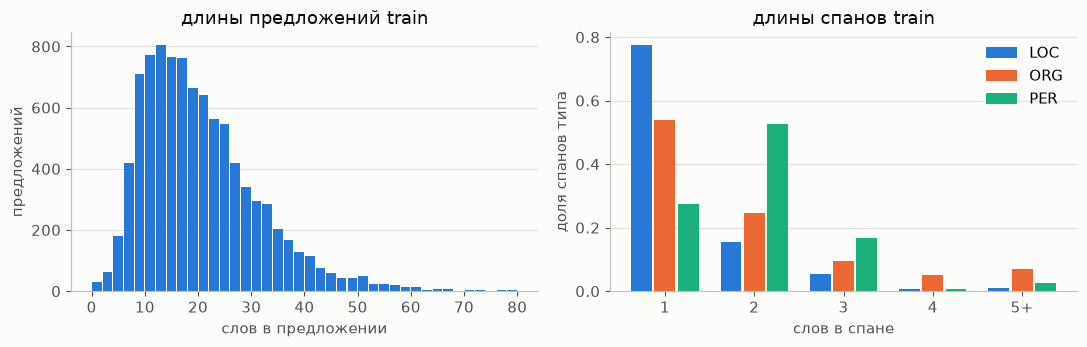

In [15]:
TYPE_ORDER = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
TYPE_COLORS = dict(zip(TYPE_ORDER, ['#2a78d6', '#eb6834', '#1baf7a']))
spans_by_split = {split: [get_entities([LABEL_NAMES[i] for i in tags]) for tags in ds['ner_tags']]
                  for split, ds in raw.items()}

print(f'{"сплит":<12}{"предл.":>8}{"слов":>9}{"без сущн.":>11}' + ''.join(f'{t:>8}' for t in TYPE_ORDER) + f'{"всего":>8}')
for split, ds in raw.items():
    counts = collections.Counter(kind for spans in spans_by_split[split] for kind, _, _ in spans)
    n_words = sum(len(ws) for ws in ds['tokens'])
    n_empty = sum(not spans for spans in spans_by_split[split])
    print(f'{split:<12}{len(ds):>8}{n_words:>9}{n_empty:>11}' + ''.join(f'{counts[t]:>8}' for t in TYPE_ORDER) + f'{sum(counts.values()):>8}')

sent_lengths = {split: np.array([len(ws) for ws in ds['tokens']]) for split, ds in raw.items()}
for split, lengths in sent_lengths.items():
    p50, p95, p99 = np.percentile(lengths, [50, 95, 99])
    print(f'{split}: длина предложения в словах: среднее {lengths.mean():.1f}, медиана {p50:.0f}, p95 {p95:.0f}, p99 {p99:.0f}, максимум {lengths.max()}')

span_lengths = collections.defaultdict(collections.Counter)
for spans in spans_by_split['train']:
    for kind, start, end in spans:
        span_lengths[kind][min(end - start + 1, 5)] += 1
print('доли спанов train по длине в словах (5 - это 5 и больше):')
for kind in TYPE_ORDER:
    n = sum(span_lengths[kind].values())
    print(f'{kind}: ' + ', '.join(f'{k}: {span_lengths[kind][k] / n:.1%}' for k in range(1, 6)) + f', средняя {sum(k * v for k, v in span_lengths[kind].items()) / n:.2f}')

train_sents = {tuple(ws) for ws in raw['train']['tokens']}
train_mentions = {' '.join(ws[s:e + 1]) for ws, spans in zip(raw['train']['tokens'], spans_by_split['train']) for _, s, e in spans}
for split in ['validation', 'test']:
    mentions = [' '.join(ws[s:e + 1]) for ws, spans in zip(raw[split]['tokens'], spans_by_split[split]) for _, s, e in spans]
    n_dup = sum(tuple(ws) in train_sents for ws in raw[split]['tokens'])
    print(f'{split}: предложений с точной копией в train {n_dup} ({n_dup / len(raw[split]):.1%}), '
          f'упоминаний с тем же текстом в train {np.mean([m in train_mentions for m in mentions]):.1%}')

word_tags = collections.defaultdict(collections.Counter)
for ws, tags in zip(raw['train']['tokens'], raw['train']['ner_tags']):
    for w, t in zip(ws, tags):
        word_tags[w][LABEL_NAMES[t][2:] or 'O'] += 1
entity_words = [w for w, c in word_tags.items() if set(c) - {'O'}]
ambiguous = [w for w in entity_words if len(set(word_tags[w]) - {'O'}) > 1]
print(f'train: уникальных слов {len(word_tags)}, внутри сущностей {len(entity_words)}, из них с разными типами {len(ambiguous)}')


def second_type_count(w):
    return sorted(v for k, v in word_tags[w].items() if k != 'O')[-2]


for w in sorted((w for w in ambiguous if w.isalpha()), key=second_type_count, reverse=True)[:8]:
    print(f'  {w}: {dict(word_tags[w].most_common())}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(sent_lengths['train'], bins=range(0, 81, 2), color=TYPE_COLORS[TYPE_ORDER[0]], rwidth=0.9)
axes[0].set_xlabel('слов в предложении')
axes[0].set_ylabel('предложений')
axes[0].set_title('длины предложений train')
axes[0].grid(True, axis='y')
width = 0.26
for k, kind in enumerate(TYPE_ORDER):
    n = sum(span_lengths[kind].values())
    axes[1].bar(np.arange(1, 6) + (k - 1) * width, [span_lengths[kind][i] / n for i in range(1, 6)],
                width=width * 0.9, color=TYPE_COLORS[kind], label=kind)
axes[1].set_xticks(range(1, 6), ['1', '2', '3', '4', '5+'])
axes[1].set_xlabel('слов в спане')
axes[1].set_ylabel('доля спанов типа')
axes[1].set_title('длины спанов train')
axes[1].grid(True, axis='y')
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Collection3 ([`RCC-MSU/collection3`](https://huggingface.co/datasets/RCC-MSU/collection3), parquet-ветка, коммит `2398327de1579acc44942636f27b8de1dcc69c1b`) состоит из русских новостей коллекции Persons-1000: 1000 документов, где изначально разметили только персоны. Организации и локации доразметили вручную в Brat по правилам, близким к MUC-7. В IOB2 корпус перевела и разбила на сплиты команда DeepPavlov (Mozharova, Loukachevitch, 2016). Разметка ручная. В карточке стоит лицензия `other`, раздел Licensing Information не заполнен; датасет входит в список разрешённых в задании.

Типов три: PER, ORG, LOC. Сущностей в train 18 247 (PER 7 406, ORG 5 960, LOC 4 881), в validation 4 117, в test 4 001, предложений 9 301 / 2 153 / 1 922. Редких типов нет, самый малочисленный LOC даёт около 27% упоминаний. Предложения короткие: в среднем 20 слов, медиана 18, p99 57, но хвост тянется до 256 слов. В 19.5% предложений train сущностей нет.

Что повлияет на обучение. Спаны у типов разной длины: LOC в 78% случаев из одного слова, PER чаще из двух (имя и фамилия, 53%), ORG длиннее и разнороднее остальных: 7% спанов из пяти слов и больше, кавычки, родовые слова вроде «Высший военный совет». Поэтому больше всего ошибок границ жду на ORG. Есть неоднозначность типа: «России» размечена как LOC 334 раза и как ORG 145 раз (например, внутри «Единой России»), «Россия» как ORG 82 раза и как LOC 30, «Москвы» как LOC 189 и ORG 28. Тексты сильно повторяются: 60.4% упоминаний validation встречаются в train слово в слово, а 2.5% предложений validation точно копируют предложения train. Часть качества, значит, даст запоминание. Шум разметки небольшой: 5 предложений train и 1 test начинают сущность с `I-` без `B-`.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [16]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, kind = [], None, None
    for i, tag in enumerate(tags):
        prefix, _, name = tag.partition('-')
        if prefix == 'I' and name == kind:
            continue
        if kind is not None:
            spans.append((start, i, kind))
        start, kind = (i, name) if prefix in ('B', 'I') else (None, None)
    if kind is not None:
        spans.append((start, len(tags), kind))
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, kind in spans:
        for i in range(start, min(end, n_words)):
            tags[i] = f'B-{kind}' if i == start else f'I-{kind}'
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, seen = [], set()
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w not in seen:
            labels.append(word_labels[w])
            seen.add(w)
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
    return labels

In [17]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [18]:
def has_orphan_i(tags):
    return any(t.startswith('I-') and (i == 0 or tags[i - 1][2:] != t[2:]) for i, t in enumerate(tags))


DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
for split, ds in raw.items():
    path = DATA_DIR / f'{split}_spans.jsonl'
    source = [[LABEL_NAMES[i] for i in tags] for tags in ds['ner_tags']]
    with path.open('w', encoding='utf-8') as f:
        for ws, tags in zip(ds['tokens'], source):
            f.write(json.dumps(dict(tokens=ws, spans=bio_to_spans(tags)), ensure_ascii=False) + '\n')
    with path.open(encoding='utf-8') as f:
        back = [json.loads(line) for line in f]
    restored = [spans_to_bio([tuple(s) for s in r['spans']], len(r['tokens'])) for r in back]

    assert [r['tokens'] for r in back] == [list(ws) for ws in ds['tokens']]
    assert all(bio_to_spans(a) == bio_to_spans(b) for a, b in zip(source, restored))
    assert all(bio_to_spans(tags) == [(s, e + 1, t) for t, s, e in get_entities(tags)] for tags in source)
    assert all(len(ws) == len(tags) and len(ws) > 0 for ws, tags in zip(ds['tokens'], source))

    n_diff = sum(a != b for a, b in zip(source, restored))
    n_orphan = sum(has_orphan_i(tags) for tags in source)
    assert n_diff == n_orphan
    bad_words = [w for ws in ds['tokens'] for w in ws if not w.strip() or ' ' in w]
    print(f'{split}: {len(back)} предложений, {sum(len(r["spans"]) for r in back)} спанов, '
          f'дословно не совпало {n_diff}, с I- без B- {n_orphan}, слов с пробелами или пустых {len(bad_words)}')

train: 9301 предложений, 18247 спанов, дословно не совпало 5, с I- без B- 5, слов с пробелами или пустых 0


validation: 2153 предложений, 4117 спанов, дословно не совпало 0, с I- без B- 0, слов с пробелами или пустых 0


test: 1922 предложений, 4001 спанов, дословно не совпало 1, с I- без B- 1, слов с пробелами или пустых 0


In [19]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']


train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и                  16  O
МВД                17  B-ORG
по                 18  O
субъектам          19  O
РФ                 20  B-LOC
.                  21  O
[SEP]            None  -100


In [20]:
for split, ds in data.items():
    n_trunc = lost_trunc = lost_empty = lost_entity = 0
    empty_words = collections.Counter()
    for ws, tags in zip(ds['tokens'], ds['ner_tags']):
        full_ids = tokenizer(ws, is_split_into_words=True).word_ids()
        kept = set(tokenizer(ws, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH).word_ids()) - {None}
        has_subwords = set(full_ids) - {None}
        n_trunc += len(full_ids) > MAX_LENGTH
        for w, (word, tag) in enumerate(zip(ws, tags)):
            if w not in has_subwords:
                lost_empty += 1
                empty_words[repr(word)] += 1
            elif w not in kept:
                lost_trunc += 1
            lost_entity += w not in kept and tag != label2id['O']
    print(f'{split}: обрезано предложений {n_trunc}, слов за обрезкой {lost_trunc}, слов без сабвордов {lost_empty} '
          f'{dict(empty_words)}, из потерянных слов внутри сущностей {lost_entity}')

train: обрезано предложений 10, слов за обрезкой 430, слов без сабвордов 4 {"'\\xad'": 4}, из потерянных слов внутри сущностей 168


validation: обрезано предложений 1, слов за обрезкой 7, слов без сабвордов 0 {}, из потерянных слов внутри сущностей 4


test: обрезано предложений 1, слов за обрезкой 15, слов без сабвордов 1 {"'\\xad'": 1}, из потерянных слов внутри сущностей 0


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метку получает только первый сабворд, потому что оцениваю по словам: тег слова берётся с его первого сабворда. Если размечать все сабворды, длинное слово из 3-4 кусков весило бы в loss в несколько раз больше короткого. −100 служит `ignore_index` в `CrossEntropyLoss`: такие позиции выпадают и из суммы, и из числа слагаемых при усреднении, градиента от них нет. Спецтокены и паддинг тоже получают −100.

По `MAX_LENGTH = 128` обрезано 10 предложений train (430 слов за обрезкой, из них 168 внутри сущностей), одно предложение validation (7 слов, 4 из них внутри сущностей) и одно test (15 слов, сущностей среди них нет). Без единого сабворда осталось 5 слов, и все они мягкий перенос `\xad`: токенизатор выбрасывает его целиком. На метрику это почти не влияет. Потерянные слова получают тег `O`, поэтому на validation 4 слова сущностей уйдут в пропуски или ошибки границ, на test потерь нет. Обучение теряет 168 размеченных слов из 187 656.

При конвертации нашлись 5 предложений train и 1 test, где сущность начинается с `I-` без `B-`. Спаны у них совпадают с seqeval, а дословно BIO после обратной сборки расходится (`I-` превращается в `B-`); остальные предложения проходят туда и обратно один в один. Вложенных и пересекающихся спанов нет, разметка плоская. Слов с пробелами и пустых слов тоже нет. На всём корпусе `bio_to_spans` совпадает со спанами из seqeval.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [21]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [22]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: c.most_common(1)[0][0] for word, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, 'O') for word in words]

In [23]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [predict_majority(tagger, ws) for ws in val_tokens]

set_seed(SEED)
random_model = make_model()
random_pred, random_conf = predict_word_tags(random_model, val_tokens, return_probs=True)
del random_model

baseline = dict(majority=entity_scores(val_gold, majority_pred), random_head=entity_scores(val_gold, random_pred))
for name, row in baseline.items():
    print(name, {k: round(v, 3) for k, v in row.items()})

val_words = [w for ws in val_tokens for w in ws]
print(f'размер словаря {len(tagger)}, слов validation вне словаря {np.mean([w not in tagger for w in val_words]):.1%}')
print(f'доля слов с тегом не O: истина {np.mean([t != "O" for tags in val_gold for t in tags]):.1%}, '
      f'случайная голова {np.mean([t != "O" for tags in random_pred for t in tags]):.1%}')
print('теги случайной головы:', collections.Counter(t for tags in random_pred for t in tags).most_common())
print(f'средняя уверенность случайной головы {np.mean([p for probs in random_conf for p in probs]):.3f}, '
      f'равномерная 1/{len(LABEL_NAMES)} = {1 / len(LABEL_NAMES):.3f}')

majority {'f1_micro': np.float64(0.561), 'f1_macro': np.float64(0.579), 'precision': np.float64(0.563), 'recall': np.float64(0.56)}
random_head {'f1_micro': np.float64(0.038), 'f1_macro': np.float64(0.035), 'precision': np.float64(0.022), 'recall': np.float64(0.13)}
размер словаря 27410, слов validation вне словаря 11.2%
доля слов с тегом не O: истина 16.6%, случайная голова 73.7%
теги случайной головы: [('O', 11544), ('I-PER', 11459), ('B-PER', 8688), ('I-LOC', 4833), ('B-LOC', 3053), ('I-ORG', 2511), ('B-ORG', 1768)]
средняя уверенность случайной головы 0.216, равномерная 1/7 = 0.143


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн даёт на validation F1 0.561 (P 0.563, R 0.560, macro 0.579). Для новостей это немало: 60% упоминаний validation дословно встречались в train, а частые LOC однословные и повторяются сотни раз («России» размечена LOC 334 раза), их хватает запомнить. Ломается бейзлайн на трёх вещах. Во-первых, 11.2% слов validation нет в словаре, и они получают `O`. Во-вторых, неоднозначное слово получает один тег на все контексты: «России» всегда LOC, хотя в «Единой России» это часть ORG. В-третьих, многословная ORG собирается, только если у каждого слова подходящий B/I, а служебные слова внутри названий («по», «и») словарь считает `O`.

Энкодер со случайной головой даёт F1 0.038. Он помечает не-`O` 73.7% слов при 16.6% в разметке, чаще всего ставит `I-PER` и `B-PER`, средняя уверенность 0.216 при равномерной 1/7 = 0.143. Предобученный энкодер выдаёт осмысленные векторы, но случайная `Linear(312, 7)` проецирует их на теги произвольно: какой тег соответствует какому направлению в пространстве, задаёт только обученная голова. Recall 0.13 набирается случайными попаданиями, а precision 0.022 топит F1.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [24]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        for name, p in model.named_parameters():
            p.requires_grad = name.startswith('classifier.')
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    every = max(1, total_steps // 20)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=64,
        weight_decay=0.01, warmup_steps=total_steps // 10,
        eval_strategy='steps', eval_steps=every, logging_strategy='steps', logging_steps=every,
        save_strategy='no', fp16=device.type == 'cuda', use_cpu=device.type == 'cpu', report_to='none', seed=SEED,
        disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds, processing_class=tok,
                      data_collator=DataCollatorForTokenClassification(tok))
    trainer.remove_callback(PrinterCallback)
    start = time.perf_counter()
    trainer.train()
    return trainer.state.log_history, time.perf_counter() - start

обучение: 2480.8 c на Intel(R) Core(TM) i7-9750H CPU @ 2.60GHz (6 потоков), 9301 предложений, 6 эпох(а)


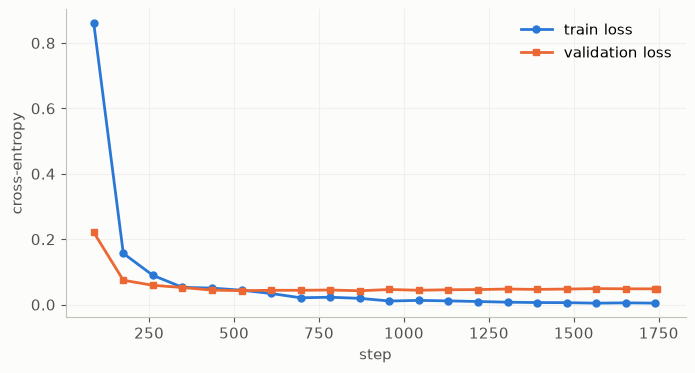

In [25]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

In [26]:
CHECK_LR = 5e-4
set_seed(SEED)
probe = make_model()
probe_history, probe_seconds = train_ner(probe, tokenized['train'], tokenized['validation'], lr=CHECK_LR, out_dir='runs/lr_check')
lr_check = {}
for lr, m, hist in [(LR, model, history), (CHECK_LR, probe, probe_history)]:
    eval_curve_lr = [h['eval_loss'] for h in hist if 'eval_loss' in h]
    lr_check[lr] = dict(val_f1=f1_score(val_gold, predict_word_tags(m, val_tokens), zero_division=0),
                        final_eval_loss=eval_curve_lr[-1], min_eval_loss=min(eval_curve_lr))
    print(f'lr {lr:g}: F1 на validation {lr_check[lr]["val_f1"]:.4f}, validation loss в конце {eval_curve_lr[-1]:.4f}, минимум {min(eval_curve_lr):.4f}')
print(f'контрольный прогон занял {probe_seconds:.0f} c')
del probe

lr 0.0002: F1 на validation 0.9352, validation loss в конце 0.0482, минимум 0.0424


lr 0.0005: F1 на validation 0.9289, validation loss в конце 0.0558, минимум 0.0494
контрольный прогон занял 1126 c


**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** lr 2e-4 предлагает шаблон для rubert-tiny2, и проверка это подтвердила: модели из трёх слоёв с hidden 312 нужен шаг крупнее, чем base-моделям (2e-5…5e-5). Контрольный прогон с lr 5e-4 по тому же протоколу дал на validation F1 0.9289 против 0.9352 и минимум validation loss 0.0494 против 0.0424. В предварительном прогоне 5e-4 тоже отставал после каждой из первых четырёх эпох. Batch 32 выбран как компромисс между шумом градиента и скоростью на CPU. Warmup на 10% шагов (174 из 1746) бережёт предобученные веса, пока голова ещё случайная. Weight decay 0.01 стандартен для AdamW в BERT, после warmup lr линейно падает до нуля. fp16 включается только на CUDA, у меня CPU. Эпох шесть, а не три: в предварительном прогоне F1 на validation рос с 0.920 после третьей эпохи до 0.937 после шестой.

На кривых train loss падает ниже 0.01 и продолжает снижаться, а validation loss к ~500-му шагу выходит на плато около 0.043 (минимум 0.0424) и к концу слегка поднимается до 0.0482. По loss это мягкое переобучение: модель становится увереннее, в том числе на своих ошибках, и cross-entropy штрафует их сильнее. F1 по сущностям при этом растёт до последней эпохи, но прирост между пятой и шестой эпохой в предварительном прогоне был всего 0.003. Значит, больше эпох почти ничего не даст, а при более длинном обучении стоило бы сохранять лучший по F1 на validation чекпойнт.

Обучение заняло 2481 с (41 мин) на CPU Intel Core i7-9750H (6 потоков), включая 20 оценок validation loss. Ноутбук при этом сильно троттлил (`CPU_Speed_Limit` падал до 22%), без троттлинга предварительный прогон тех же шести эпох занял 13 минут.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [27]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = n_gold = n_pred = 0
    for gold_tags, pred_tags in zip(gold, pred):
        for g, p in zip(gold_tags, pred_tags):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += p != 'O' and p == g
    return 2 * tp / (n_gold + n_pred) if n_gold + n_pred else 0.0

In [28]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0


def full_report(gold, pred):
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    per_type = {t: report[t] for t in ENTITY_TYPES if t in report}
    return dict(entity_scores(gold, pred), token_f1=token_f1(gold, pred), per_type=per_type)


def bootstrap_f1(gold, pred, n_boot=2000, seed=SEED):
    rows = []
    for g_tags, p_tags in zip(gold, pred):
        g_spans, p_spans = set(bio_to_spans(g_tags)), set(bio_to_spans(p_tags))
        rows.append((len(g_spans & p_spans), len(g_spans), len(p_spans)))
    rows = np.array(rows)
    idx = np.random.default_rng(seed).integers(0, len(rows), (n_boot, len(rows)))
    tp, n_gold, n_pred = rows[idx].sum(axis=1).T
    return np.percentile(2 * tp / np.maximum(n_gold + n_pred, 1), [2.5, 97.5])


test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)

final = full_report(test_gold, test_pred)
final_val = full_report(val_gold, val_pred)
final['f1_micro_ci95'] = bootstrap_f1(test_gold, test_pred)
final_val['f1_micro_ci95'] = bootstrap_f1(val_gold, val_pred)

for name, gold_tags, pred_tags, row in [('validation', val_gold, val_pred, final_val), ('test', test_gold, test_pred, final)]:
    print(name)
    print(classification_report(gold_tags, pred_tags, digits=3, zero_division=0))
    ci = row['f1_micro_ci95']
    print(f'F1 по сущностям micro {row["f1_micro"]:.4f} (95% бутстреп по предложениям {ci[0]:.4f} - {ci[1]:.4f}), '
          f'macro {row["f1_macro"]:.4f}, токенный F1 {row["token_f1"]:.4f}\n')

majority_test = [predict_majority(tagger, ws) for ws in test_tokens]
print(f'словарный бейзлайн: validation {f1_score(val_gold, majority_pred, zero_division=0):.4f}, test {f1_score(test_gold, majority_test, zero_division=0):.4f}')

validation


              precision    recall  f1-score   support

         LOC      0.959     0.959     0.959      1168
         ORG      0.843     0.890     0.866      1308
         PER      0.964     0.985     0.975      1641

   micro avg      0.923     0.948     0.935      4117
   macro avg      0.922     0.945     0.933      4117
weighted avg      0.924     0.948     0.936      4117

F1 по сущностям micro 0.9352 (95% бутстреп по предложениям 0.9263 - 0.9434), macro 0.9331, токенный F1 0.9554

test


              precision    recall  f1-score   support

         LOC      0.946     0.963     0.955      1175
         ORG      0.850     0.879     0.864      1256
         PER      0.959     0.978     0.969      1570

   micro avg      0.921     0.943     0.932      4001
   macro avg      0.919     0.940     0.929      4001
weighted avg      0.921     0.943     0.932      4001

F1 по сущностям micro 0.9317 (95% бутстреп по предложениям 0.9230 - 0.9402), macro 0.9293, токенный F1 0.9552



словарный бейзлайн: validation 0.5613, test 0.5273


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Хуже всего распознаются ORG: F1 0.864 на test против 0.955 у LOC и 0.969 у PER (на validation 0.866 / 0.959 / 0.975). Дело не в частоте: организаций в train 5 960, больше, чем локаций (4 881). ORG длиннее (в среднем 1.87 слова, 7% спанов из пяти слов и больше) и разнороднее: аббревиатуры, названия в кавычках, длинные описательные имена вроде «Кольской горно-металлургической кампании». Чем длиннее спан, тем больше шансов промахнуться хотя бы на одну границу. К тому же ORG путается с LOC при метонимии: «Россия» как государство-участник размечена ORG 82 раза и LOC 30. Precision у ORG тоже самый низкий (0.850): модель охотно объявляет организацией любую аббревиатуру или название в кавычках.

Micro F1 (0.932 на test) считается по всем спанам сразу, macro (0.929) усредняет F1 трёх типов. Они почти совпадают, потому что типы сбалансированы, а самый массовый PER (1 570 спанов в test) распознаётся лучше всех. Macro чуть ниже из-за ORG, который в нём весит ровно треть.

Токенный F1 выше: 0.955 против 0.932 на test (на validation 0.955 против 0.935). Он даёт частичный зачёт. Если в «Кольской горно-металлургической кампании» модель потеряла последнее слово, по словам верны 3 из 4, а по сущностям спан провален целиком, причём дважды: истинный спан не найден, а предсказанный лишний. Ошибки границ — самая частая категория (см. 5.1), отсюда и заметный разрыв. Пользователю NER ближе F1 по сущностям: ему нужна сущность целиком, «Румынский правый альянс», а не «Румынский правый». Обрезанное название в поиске или в базе знаний бесполезно.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [29]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def overlap(a, b):
        return min(a[1], b[1]) - max(a[0], b[0])

    result = []
    for g in gold_spans:
        touching = [p for p in pred_spans if overlap(g, p) > 0]
        same_type = [p for p in touching if p[2] == g[2]]
        if g in pred_spans:
            result.append(('correct', g, g))
        elif same_type:
            result.append(('boundary', g, max(same_type, key=lambda p: overlap(g, p))))
        elif touching:
            result.append(('type', g, max(touching, key=lambda p: overlap(g, p))))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if not any(overlap(g, p) > 0 for g in gold_spans):
            result.append(('spurious', None, p))
    return result

In [30]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

error_rows = [(i, *row) for i, (g, p) in enumerate(zip(val_gold, val_pred))
              for row in categorize_errors(bio_to_spans(g), bio_to_spans(p))]
errors = {c: sum(row[1] == c for row in error_rows) for c in ERROR_CATEGORIES}

n_gold = sum(errors[c] for c in ['correct', 'boundary', 'type', 'missed'])
n_pred_spans = sum(len(bio_to_spans(p)) for p in val_pred)
assert n_gold == sum(len(bio_to_spans(g)) for g in val_gold)
assert abs(errors['correct'] / n_gold - recall_score(val_gold, val_pred, zero_division=0)) < 1e-9
assert abs(errors['correct'] / max(n_pred_spans, 1) - precision_score(val_gold, val_pred, zero_division=0)) < 1e-9

n_errors = sum(v for c, v in errors.items() if c != 'correct')
print(f'истинных спанов {n_gold}, предсказанных {n_pred_spans}, ошибок {n_errors}')
for c in ERROR_CATEGORIES:
    share = '' if c == 'correct' else f', {errors[c] / n_errors:.1%} ошибок'
    print(f'{c:<10}{errors[c]:>6}{share}')

print(f'\n{"тип":<6}' + ''.join(f'{c:>10}' for c in ERROR_CATEGORIES))
for kind in ENTITY_TYPES:
    cells = [sum(row[1] == c and (row[2] or row[3])[2] == kind for row in error_rows) for c in ERROR_CATEGORIES]
    print(f'{kind:<6}' + ''.join(f'{v:>10}' for v in cells))

type_pairs = collections.Counter((row[2][2], row[3][2]) for row in error_rows if row[1] == 'type')
print('\nошибки типа (истина, предсказание):', type_pairs.most_common())


def boundary_kind(g, p):
    if p[0] <= g[0] and p[1] >= g[1]:
        return 'предсказание шире'
    if p[0] >= g[0] and p[1] <= g[1]:
        return 'предсказание уже'
    return 'сдвиг'


print('ошибки границы:', collections.Counter(boundary_kind(row[2], row[3]) for row in error_rows if row[1] == 'boundary').most_common())


def span_text(i, span):
    return ' '.join(val_tokens[i][span[0]:span[1]])


seen_mentions = {' '.join(ws[s:e]) for ws, tags in zip(data['train']['tokens'], data['train']['ner_tags'])
                 for s, e, _ in bio_to_spans([LABEL_NAMES[i] for i in tags])}
missed_rows = [row for row in error_rows if row[1] == 'missed']
print(f'пропуски: длиной в одно слово {np.mean([r[2][1] - r[2][0] == 1 for r in missed_rows]):.1%}, '
      f'текст упоминания встречался в train {np.mean([span_text(r[0], r[2]) in seen_mentions for r in missed_rows]):.1%}; '
      f'для верных спанов {np.mean([span_text(r[0], r[2]) in seen_mentions for r in error_rows if r[1] == "correct"]):.1%}')
print('частые тексты в пропусках:', collections.Counter(span_text(r[0], r[2]) for r in missed_rows).most_common(10))
print('частые тексты в лишних спанах:', collections.Counter(span_text(r[0], r[3]) for r in error_rows if r[1] == 'spurious').most_common(10))


def show_error(i, category, g, p):
    gold_text = f'{span_text(i, g)} [{g[2]}]' if g else '-'
    pred_text = f'{span_text(i, p)} [{p[2]}]' if p else '-'
    print(f'{category}: истина: {gold_text} | предсказание: {pred_text}\n    {" ".join(val_tokens[i])}')


example_rng = random.Random(SEED)
for c in ERROR_CATEGORIES[1:]:
    rows = [row for row in error_rows if row[1] == c]
    print()
    for row in example_rng.sample(rows, min(5, len(rows))):
        show_error(*row)

истинных спанов 4117, предсказанных 4226, ошибок 322
correct     3901
boundary     147, 45.7% ошибок
type          43, 13.4% ошибок
missed        26, 8.1% ошибок
spurious     106, 32.9% ошибок

тип      correct  boundary      type    missed  spurious
LOC         1120        14        28         6        19
ORG         1164       117         9        18        76
PER         1617        16         6         2        11

ошибки типа (истина, предсказание): [(('LOC', 'PER'), 18), (('LOC', 'ORG'), 10), (('ORG', 'LOC'), 5), (('ORG', 'PER'), 4), (('PER', 'LOC'), 4), (('PER', 'ORG'), 2)]
ошибки границы: [('предсказание уже', 83), ('предсказание шире', 64)]


пропуски: длиной в одно слово 57.7%, текст упоминания встречался в train 11.5%; для верных спанов 62.9%
частые тексты в пропусках: [('ПМР', 3), ('Белорусской калийной компании', 2), ('Подъем', 1), ('Заксобрание', 1), ('Верховным судом', 1), ('Ираком', 1), ('FM - радиостанцию', 1), ('Яйлю', 1), ('Системного оператора', 1), ('Министерство иностранных дел', 1)]
частые тексты в лишних спанах: [('ВИЭ', 12), ('Конституционную декларацию', 5), ('iOS', 3), ('Дипломат', 3), ('Sukhoi SuperJet', 2), ('России', 2), ('Совет директоров', 2), ('"', 2), ('Google', 2), ('Протон', 2)]

boundary: истина: Кольской горно - металлургической кампании [ORG] | предсказание: Кольской горно - металлургической [ORG]
    До назначения и . о . губернатора она работала заместителем гендиректора Кольской горно - металлургической кампании ( дочернее предприятие ОАО " Норильский никель " ) и возглавляла фракцию " Единой России " в областном Заксобрании .
boundary: истина: Румынский правый альянс [ORG] | предсказание: Р

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Самая частая категория — ошибки границы: 147 из 322 ошибок на validation (45.7%), из них 117 приходятся на ORG. Дальше идут лишние спаны (106, 32.9%), ошибки типа (43, 13.4%) и пропуски (26, 8.1%). Верно найдено 3 901 из 4 117 сущностей.

Что общего у примеров внутри категорий:
- в ошибках границы это длинные названия организаций и кавычки. Модель то теряет хвост («Кольской горно-металлургической [кампании]», «Румынский правый [альянс]») или закрывающую кавычку, то прихватывает лишнее («зять Назарбаева», «News of The World )»). Предсказание уже истинного спана в 83 случаях, шире в 64;
- лишние спаны дают аббревиатуры и названия, которые похожи на организации, но не размечены ими: «ВИЭ» (возобновляемые источники энергии) 12 раз, все в одной статье про энергетику, «Конституционную декларацию», продукты iOS и Sukhoi SuperJet. Сюда же попадает слово с большой буквы в начале предложения («Дипломат утверждал…» → PER);
- ошибки типа случаются на редких топонимах, похожих на фамилии («Пичаевский» район, «Лихтенштейне» → PER, всего LOC→PER 18 случаев), и при метонимии LOC/ORG («аэропорта Домодедово», «Томск»);
- пропускает модель незнакомые сущности. Только 11.5% пропущенных упоминаний встречались в train, а у верно найденных таких 62.9%. Это редкие имена в косвенных падежах («Понты», «Ираком»), аббревиатуры («ПМР») и организации из обычных слов со строчной буквы («Системного оператора»).

Часть ошибок на самом деле объясняется разметкой. Кавычки в ORG размечены непоследовательно: в «НПО " Специальная техника и связь "» они входят в спан, а в «" Румынский правый альянс "» остаются снаружи, поэтому ошибка с закрывающей кавычкой во многом шум разметки. «Google» в «Google Maps» размечен как `O`, хотя в соседних предложениях Google размечен ORG. «Центр» как зона футбольной лиги размечен LOC, «Домодедово» в «аэропорта Домодедово» — ORG. Такие случаи спорные, и модель ошибается там же, где разошлись бы два аннотатора. А вот «ВИЭ», «Дипломат» и «зять Назарбаева» — честные ошибки модели.

Чтобы сократить ошибки границ, сначала стоит унифицировать кавычки в разметке train (например, всегда оставлять их снаружи спана) и обрезать кавычки и скобки на краях предсказанных спанов постобработкой. Следующим шагом попробую модель крупнее (rubert-base) и CRF-слой поверх логитов, который штрафует несогласованные последовательности B/I.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [31]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'


def count_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                           freeze_encoder=True, out_dir='runs/freeze')
frozen_pred = predict_word_tags(frozen_model, val_tokens)

HEAD_LR = 5e-3
set_seed(SEED)
frozen_lr_model = make_model()
frozen_lr_history, frozen_lr_seconds = train_ner(frozen_lr_model, tokenized['train'], tokenized['validation'], lr=HEAD_LR,
                                                 freeze_encoder=True, out_dir='runs/freeze_lr')
frozen_lr_pred = predict_word_tags(frozen_lr_model, val_tokens)

ablation = dict(
    setting=ABLATION, split='validation', epochs=EPOCHS, lr=LR,
    full=dict(entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred),
              train_sec=train_seconds, trainable_params=count_trainable(model)),
    freeze=dict(entity_scores(val_gold, frozen_pred), token_f1=token_f1(val_gold, frozen_pred),
                train_sec=frozen_seconds, trainable_params=count_trainable(frozen_model)),
    freeze_head_lr=dict(entity_scores(val_gold, frozen_lr_pred), token_f1=token_f1(val_gold, frozen_lr_pred), lr=HEAD_LR,
                        train_sec=frozen_lr_seconds, trainable_params=count_trainable(frozen_lr_model)))
for name in ['full', 'freeze', 'freeze_head_lr']:
    row = ablation[name]
    print(f'{name:<15} F1 micro {row["f1_micro"]:.4f}, macro {row["f1_macro"]:.4f}, P {row["precision"]:.4f}, R {row["recall"]:.4f}, '
          f'токенный F1 {row["token_f1"]:.4f}, время {row["train_sec"]:.0f} c, обучаемых параметров {row["trainable_params"]:,}')
for name, hist in [('freeze', frozen_history), (f'freeze, lr {HEAD_LR}', frozen_lr_history), ('full', history)]:
    curve = [(h['step'], round(h['eval_loss'], 3)) for h in hist if 'eval_loss' in h]
    print(f'validation loss {name}: начало {curve[0]}, середина {curve[len(curve) // 2]}, конец {curve[-1]}')
del frozen_model, frozen_lr_model

full            F1 micro 0.9352, macro 0.9331, P 0.9231, R 0.9475, токенный F1 0.9554, время 2481 c, обучаемых параметров 29,098,303
freeze          F1 micro 0.6643, macro 0.6562, P 0.6360, R 0.6952, токенный F1 0.7297, время 598 c, обучаемых параметров 2,191
freeze_head_lr  F1 micro 0.7731, macro 0.7720, P 0.7286, R 0.8234, токенный F1 0.8449, время 592 c, обучаемых параметров 2,191
validation loss freeze: начало (87, 1.42), середина (957, 0.212), конец (1746, 0.19)
validation loss freeze, lr 0.005: начало (87, 0.232), середина (957, 0.113), конец (1746, 0.11)
validation loss full: начало (87, 0.221), середина (957, 0.046), конец (1746, 0.048)


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Замороженный энкодер с обучаемой головой (2 191 параметр вместо 29.1 млн) даёт на validation F1 0.664 против 0.935 у полного дообучения, на 27 пунктов меньше. Учится он в 4 раза быстрее: 598 с против 2481 с. Время падает не пропорционально числу параметров, потому что прямой проход через энкодер и 20 оценок на validation остаются, а экономятся только обратный проход и шаг AdamW по 29 млн весов.

Часть провала объясняется слишком маленьким для одной линейной головы lr 2e-4: validation loss к концу обучения дошёл только до 0.19. Поэтому сразу делаю следующий шаг и обучаю ту же голову на замороженном энкодере с lr 5e-3. Получаю F1 0.773 и validation loss 0.11, но до полного дообучения (0.935, loss 0.048) всё равно 16 пунктов. Значит, признаки rubert-tiny2, которую учили в основном на сходство предложений, линейно разделяют типы сущностей только частично, а точные границы и типы требуют подстройки самих слоёв. Показательно, что у замороженной модели токенный F1 (0.845) заметно выше спанового (0.773): слова сущностей она находит, но путает B/I и границы.

Для надёжности вывода стоит повторить оба варианта на 3-5 seed (сейчас seed один, а 95% бутстреп-интервал полной модели на validation ±0.009), подобрать lr головы по сетке и проверить промежуточный вариант, где размораживается только последний слой энкодера.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообученная rubert-tiny2 (29 млн параметров) за 6 эпох на CPU даёт на test F1 по сущностям 0.932 (95% бутстреп-интервал 0.923–0.940), macro F1 0.929 и токенный F1 0.955. Для сравнения, словарный бейзлайн на test набирает 0.527, а случайная голова на validation 0.038. Сработали маленькая русская модель с большим словарём, lr 2e-4 (с 5e-4 F1 на validation ниже на 0.006) и шесть эпох вместо трёх (+0.017 F1 на validation в предварительном прогоне). Заморозка энкодера не работает: даже с подобранным lr головы F1 только 0.773. Слабое место модели — ORG (F1 0.864 на test). Почти половина ошибок приходится на границы, в основном у длинных названий организаций и названий в кавычках, а сама разметка кавычек непоследовательна: в одних ORG-спанах кавычки входят в спан, в других остаются снаружи. Ограничения эксперимента: один seed и один корпус новостей, где 60% упоминаний validation встречаются в train, поэтому на текстах другого источника качество будет ниже. Ещё одно ограничение — бюджет CPU, из-за которого не удалось сравнить с base-моделью. Дальше стоит унифицировать кавычки в разметке, попробовать rubert-base-cased и CRF-голову, а для устойчивости добавить в обучение аугментации регистра и опечаток (см. 6.3).

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [32]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "split": "validation", "epochs": 6, "lr": 0.0002, "full": {"f1_micro": 0.935155219944864, "f1_macro": 0.9331123343644282, "precision": 0.9230951254141032, "recall": 0.9475346125819771, "token_f1": 0.9554445280952707, "train_sec": 2480.813431030001, "trainable_params": 29098303}, "freeze": {"f1_micro": 0.66426830
final F1 micro 0.9317


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [33]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Не выполняю: задача требует собственной ручной разметки 50+ предложений, поэтому `'6.1'` в `BONUS_TASKS` не включён.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [34]:
if '6.2' in BONUS_TASKS:
    OTHER_ID = 'cointegrated/rubert-tiny'
    OTHER_REVISION = '5441c5ea8026d4f6d7505ec004845409f1259fb1'
    OTHER_LR = LR
    other_tok = AutoTokenizer.from_pretrained(OTHER_ID, revision=OTHER_REVISION)
    other_tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                               fn_kwargs=dict(tok=other_tok))
    set_seed(SEED)
    other_model = make_model(OTHER_ID, OTHER_REVISION)
    other_history, other_seconds = train_ner(other_model, other_tokenized['train'], other_tokenized['validation'],
                                             lr=OTHER_LR, tok=other_tok, out_dir='runs/other')


    def infer_seconds(m, tok):
        predict_word_tags(m, val_tokens[:64], tok=tok)
        start = time.perf_counter()
        predict_word_tags(m, val_tokens, tok=tok)
        return time.perf_counter() - start


    compare = {}
    for name, m, tok, seconds in [(MODEL_ID, model, tokenizer, train_seconds), (OTHER_ID, other_model, other_tok, other_seconds)]:
        val_tags = predict_word_tags(m, val_tokens, tok=tok)
        test_tags = predict_word_tags(m, test_tokens, tok=tok)
        n_params = sum(p.numel() for p in m.parameters())
        infer = infer_seconds(m, tok)
        compare[name] = dict(val_f1=f1_score(val_gold, val_tags, zero_division=0), test=full_report(test_gold, test_tags),
                             test_ci95=bootstrap_f1(test_gold, test_tags), train_sec=seconds, infer_sec=infer,
                             sent_per_sec=len(val_tokens) / infer, params=n_params, size_mb=n_params * 4 / 2 ** 20)
        row = compare[name]
        print(f'{name}: F1 validation {row["val_f1"]:.4f}, F1 test {row["test"]["f1_micro"]:.4f} '
              f'({row["test_ci95"][0]:.4f} - {row["test_ci95"][1]:.4f}), macro test {row["test"]["f1_macro"]:.4f}, '
              f'обучение {seconds:.0f} c, инференс {row["sent_per_sec"]:.0f} предл./c, параметров {n_params:,}, веса ~{row["size_mb"]:.0f} МБ')
        print('  по типам на test:', {t: round(v['f1-score'], 3) for t, v in row['test']['per_type'].items()})
    for name, tok in [(MODEL_ID, tokenizer), (OTHER_ID, other_tok)]:
        ids = tok(val_tokens, is_split_into_words=True, add_special_tokens=False)['input_ids']
        n_sub = sum(len(x) for x in ids)
        print(f'{name}: словарь {tok.vocab_size}, сабвордов на слово {n_sub / sum(len(ws) for ws in val_tokens):.2f}, '
              f'UNK {sum(x.count(tok.unk_token_id) for x in ids) / n_sub:.2%}, обрезано предложений {sum(len(x) + 2 > MAX_LENGTH for x in ids)}')
    print('одинаковые данные, seed, число эпох, batch size, lr и MAX_LENGTH, F1 считается по словам теми же функциями')
    other_model = other_model.cpu()
    del other_model

cointegrated/rubert-tiny2: F1 validation 0.9352, F1 test 0.9317 (0.9230 - 0.9402), macro test 0.9293, обучение 2481 c, инференс 399 предл./c, параметров 29,098,303, веса ~111 МБ
  по типам на test: {'LOC': np.float64(0.955), 'ORG': np.float64(0.864), 'PER': np.float64(0.969)}


cointegrated/rubert-tiny: F1 validation 0.9156, F1 test 0.9068 (0.8964 - 0.9167), macro test 0.9047, обучение 1377 c, инференс 308 предл./c, параметров 11,688,703, веса ~45 МБ
  по типам на test: {'LOC': np.float64(0.926), 'ORG': np.float64(0.845), 'PER': np.float64(0.943)}
cointegrated/rubert-tiny2: словарь 83828, сабвордов на слово 1.14, UNK 0.11%, обрезано предложений 1


cointegrated/rubert-tiny: словарь 29564, сабвордов на слово 1.74, UNK 0.07%, обрезано предложений 6
одинаковые данные, seed, число эпох, batch size, lr и MAX_LENGTH, F1 считается по словам теми же функциями


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Сравниваю rubert-tiny2 с её предшественницей `cointegrated/rubert-tiny` (ревизия `5441c5ea8026d4f6d7505ec004845409f1259fb1`, MIT). Архитектура та же (3 слоя, hidden 312), но модель двуязычная, это дистилляция mBERT на русско-английских текстах, а словарь у неё втрое меньше: 29 564 сабворда против 83 828. tiny2 лучше: F1 на test 0.932 (0.923–0.940) против 0.907 (0.896–0.917), на validation 0.935 против 0.916, бутстреп-интервалы на test не пересекаются. Выигрыш есть на всех типах: LOC 0.955 против 0.926, ORG 0.864 против 0.845, PER 0.969 против 0.943. Главная причина видна по токенизации. У rubert-tiny на слово приходится 1.74 сабворда против 1.14, редкие фамилии и топонимы режутся на куски, и узнать их труднее. Кроме того, у неё 6 предложений validation не влезают в 128 сабвордов, у tiny2 одно.

Плачу размером: 29.1 млн параметров (~111 МБ) против 11.7 млн (~45 МБ), и почти вся разница сидит в таблице эмбеддингов. Обучение tiny2 шло дольше (2481 с против 1377 с), потому что AdamW обновляет втрое большую таблицу. Инференс у неё при этом даже быстрее, 399 предложений в секунду против 308: последовательности короче, а размер таблицы на скорость выборки эмбеддинга не влияет. На троттлящем CPU время шумит на десятки процентов, так что соотношения по времени грубые.

Честность сравнения обеспечиваю так: те же данные и сплиты, тот же seed, 6 эпох, batch 32, lr 2e-4 (архитектура одинаковая, поэтому lr не перенастраиваю), `MAX_LENGTH = 128`, и F1 считается по словам одними и теми же функциями.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

без порчи              F1 0.935, P 0.923, R 0.948, сабвордов на слово 1.14, UNK 0.11%, обрезано 1, изменено слов 0.0%, LOC 0.959, ORG 0.866, PER 0.975


опечатки в 10% слов    F1 0.905, P 0.890, R 0.921, сабвордов на слово 1.24, UNK 0.10%, обрезано 1, изменено слов 6.5%, LOC 0.926, ORG 0.846, PER 0.938


опечатки в 30% слов    F1 0.826, P 0.805, R 0.848, сабвордов на слово 1.45, UNK 0.08%, обрезано 1, изменено слов 20.1%, LOC 0.856, ORG 0.776, PER 0.845


нижний регистр         F1 0.089, P 0.407, R 0.050, сабвордов на слово 1.23, UNK 0.10%, обрезано 1, изменено слов 18.3%, LOC 0.037, ORG 0.078, PER 0.131


верхний регистр        F1 0.071, P 0.046, R 0.154, сабвордов на слово 3.46, UNK 0.04%, обрезано 192, изменено слов 77.5%, LOC 0.113, ORG 0.056, PER 0.007


транслит               F1 0.112, P 0.078, R 0.200, сабвордов на слово 2.47, UNK 0.05%, обрезано 41, изменено слов 79.6%, LOC 0.012, ORG 0.079, PER 0.228


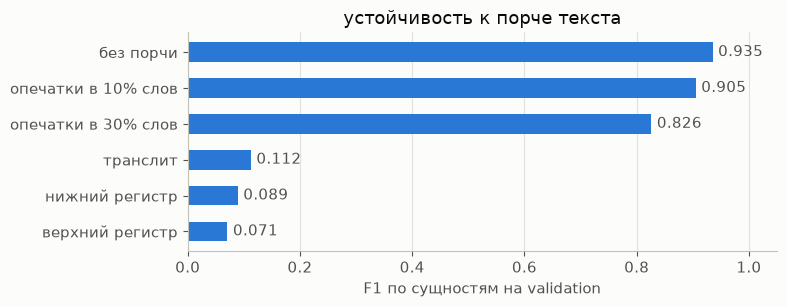

In [35]:
if '6.3' in BONUS_TASKS:
    LATIN = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя',
                     ['a', 'b', 'v', 'g', 'd', 'e', 'yo', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'f',
                      'kh', 'ts', 'ch', 'sh', 'shch', '', 'y', '', 'e', 'yu', 'ya']))


    def translit(word):
        out = ''.join(LATIN.get(ch.lower(), ch.lower()).capitalize() if ch.isupper() else LATIN.get(ch, ch) for ch in word)
        return out or word


    def add_typo(word, rng, p):
        if len(word) < 3 or not word.isalpha() or rng.random() > p:
            return word
        i = rng.randrange(len(word) - 1)
        kind = rng.choice(['swap', 'drop', 'double'])
        if kind == 'swap':
            return word[:i] + word[i + 1] + word[i] + word[i + 2:]
        if kind == 'drop':
            return word[:i] + word[i + 1:]
        return word[:i] + word[i] + word[i:]


    SHIFTS = {'без порчи': lambda w, rng: w,
              'опечатки в 10% слов': lambda w, rng: add_typo(w, rng, 0.1),
              'опечатки в 30% слов': lambda w, rng: add_typo(w, rng, 0.3),
              'нижний регистр': lambda w, rng: w.lower(),
              'верхний регистр': lambda w, rng: w.upper(),
              'транслит': lambda w, rng: translit(w)}

    shift_results = {}
    for name, corrupt in SHIFTS.items():
        rng = random.Random(SEED)
        shifted = [[corrupt(w, rng) for w in ws] for ws in val_tokens]
        assert all(len(a) == len(b) and all(b) for a, b in zip(val_tokens, shifted))
        shifted_pred = predict_word_tags(model, shifted)
        ids = tokenizer(shifted, is_split_into_words=True, add_special_tokens=False)['input_ids']
        n_sub = sum(len(x) for x in ids)
        report = full_report(val_gold, shifted_pred)
        shift_results[name] = dict(report, subwords_per_word=n_sub / sum(len(ws) for ws in shifted),
                                   unk_share=sum(x.count(tokenizer.unk_token_id) for x in ids) / n_sub,
                                   n_truncated=sum(len(x) + 2 > MAX_LENGTH for x in ids),
                                   changed_words=np.mean([a != b for ws, zs in zip(val_tokens, shifted) for a, b in zip(ws, zs)]))
        row = shift_results[name]
        print(f'{name:<22} F1 {row["f1_micro"]:.3f}, P {row["precision"]:.3f}, R {row["recall"]:.3f}, '
              f'сабвордов на слово {row["subwords_per_word"]:.2f}, UNK {row["unk_share"]:.2%}, '
              f'обрезано {row["n_truncated"]}, изменено слов {row["changed_words"]:.1%}, '
              + ', '.join(f'{t} {v["f1-score"]:.3f}' for t, v in row['per_type'].items()))

    ranked = sorted(shift_results, key=lambda k: shift_results[k]['f1_micro'])
    values = [shift_results[k]['f1_micro'] for k in ranked]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh(ranked, values, height=0.55, color='#2a78d6')
    for y, v in enumerate(values):
        ax.text(v + 0.01, y, f'{v:.3f}', va='center', color='#52514e')
    ax.set_xlim(0, 1.05)
    ax.set_xlabel('F1 по сущностям на validation')
    ax.set_title('устойчивость к порче текста')
    ax.grid(True, axis='x')
    ax.grid(False, axis='y')
    plt.tight_layout()
    plt.show()

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Сильнее всего F1 роняет смена регистра: верхний регистр даёт 0.071, нижний 0.089 при 0.935 на чистом validation, транслит 0.112. Опечатки бьют мягче: 0.905 при 10% испорченных слов и 0.826 при 30%.

Модель cased, и заглавная буква для неё главный признак сущности в русском тексте. В нижнем регистре recall падает до 0.05: модель почти перестаёт находить сущности, хотя найденное чаще верно (precision 0.41). В верхнем регистре наоборот, каждое слово похоже на аббревиатуру или имя, и precision падает до 0.046. Слов капсом словарь к тому же почти не знает и режет их в среднем на 3.46 сабворда вместо 1.14, так что 192 предложения перестают влезать в `MAX_LENGTH`. Транслит переводит текст в латиницу, где у русского словаря мало знакомых кусков (2.47 сабворда на слово). Имена в латинице ещё похожи на иностранные (PER 0.228), а локации пропадают почти полностью (LOC 0.012). Опечатка портит одно-два места в слове: WordPiece режет его на чуть большее число кусков (1.45 сабворда на слово при 30% опечаток), но заглавная буква и контекст остаются, поэтому F1 падает плавно.

Помогли бы аугментации при обучении: случайно переводить часть предложений в нижний и верхний регистр и добавлять опечатки.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [36]:
if '6.4' in BONUS_TASKS:
    %pip install -q onnx onnxruntime onnxscript
    import logging
    import warnings
    import onnxruntime as ort
    from onnxruntime.quantization import QuantType, quantize_dynamic
    from types import SimpleNamespace


    class LogitsOnly(torch.nn.Module):
        def __init__(self, inner):
            super().__init__()
            self.inner = inner

        def forward(self, input_ids, attention_mask, token_type_ids):
            return self.inner(input_ids=input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids).logits


    class OnnxTagger:
        def __init__(self, path, config):
            options = ort.SessionOptions()
            options.intra_op_num_threads = torch.get_num_threads()
            self.session = ort.InferenceSession(str(path), options, providers=['CPUExecutionProvider'])
            self.config = config

        def eval(self):
            return self

        def to(self, dev):
            return self

        def __call__(self, **enc):
            arrays = {k: v.cpu().numpy() for k, v in enc.items()}
            return SimpleNamespace(logits=torch.from_numpy(self.session.run(['logits'], arrays)[0]))


    def file_mb(path):
        return sum(p.stat().st_size for p in Path(path).parent.glob(Path(path).name + '*')) / 2 ** 20


    def mean_latency(fn, n_warm=5, n_runs=30):
        for _ in range(n_warm):
            fn()
        times = []
        for _ in range(n_runs):
            start = time.perf_counter()
            fn()
            times.append(time.perf_counter() - start)
        return float(np.mean(times) * 1000), float(np.std(times) * 1000)


    ONNX_DIR = Path('runs/onnx')
    ONNX_DIR.mkdir(parents=True, exist_ok=True)
    onnx_path, quant_path = ONNX_DIR / 'model.onnx', ONNX_DIR / 'model.quant.onnx'
    cpu = torch.device('cpu')
    cpu_model = copy.deepcopy(model).to(cpu).eval()
    sample = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
    sample = {k: sample[k] for k in ['input_ids', 'attention_mask', 'token_type_ids']}

    logging.getLogger('torch.onnx').setLevel(logging.ERROR)
    batch_dim, length_dim = torch.export.Dim('batch'), torch.export.Dim('length')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        torch.onnx.export(LogitsOnly(cpu_model).eval(), tuple(sample.values()), str(onnx_path), input_names=list(sample),
                          output_names=['logits'], dynamic_shapes=tuple({0: batch_dim, 1: length_dim} for _ in sample),
                          dynamo=True, verbose=False)
    quantize_dynamic(str(onnx_path), str(quant_path), weight_type=QuantType.QInt8)

    onnx_model = OnnxTagger(onnx_path, cpu_model.config)
    quant_model = OnnxTagger(quant_path, cpu_model.config)
    real = sample['attention_mask'].bool()
    with torch.inference_mode():
        torch_logits = cpu_model(**sample).logits
    for name, m in [('onnx', onnx_model), ('onnx int8', quant_model)]:
        logits = m(**sample).logits
        agree = (logits.argmax(-1) == torch_logits.argmax(-1))[real].float().mean()
        print(f'{name}: максимальное отличие логитов от torch на реальных токенах {(logits - torch_logits).abs()[real].max():.2e}, '
              f'совпадение argmax {agree:.2%}')

    single = {k: v[:1] for k, v in sample.items()}
    speed = {}
    for name, m, path in [('torch cpu', cpu_model, None), ('onnx', onnx_model, onnx_path), ('onnx int8', quant_model, quant_path)]:
        def run_batch():
            with torch.inference_mode():
                m(**sample)

        def run_single():
            with torch.inference_mode():
                m(**single)

        batch_mean, batch_std = mean_latency(run_batch)
        single_mean, single_std = mean_latency(run_single)
        tags = predict_word_tags(m, val_tokens, dev=cpu)
        speed[name] = dict(batch_ms=batch_mean, batch_std=batch_std, single_ms=single_mean, single_std=single_std,
                           f1=f1_score(val_gold, tags, zero_division=0), size_mb=file_mb(path) if path else None)
        row = speed[name]
        size = f'{row["size_mb"]:.1f} МБ' if path else f'{sum(p.numel() for p in cpu_model.parameters()) * 4 / 2 ** 20:.1f} МБ (веса float32)'
        print(f'{name:<10} батч {sample["input_ids"].shape[0]} x {sample["input_ids"].shape[1]}: {batch_mean:.1f} ± {batch_std:.1f} мс, '
              f'одно предложение: {single_mean:.2f} ± {single_std:.2f} мс, F1 validation {row["f1"]:.4f}, размер {size}')
    print(f'устройство {DEVICE_NAME}, потоков torch и onnxruntime {torch.get_num_threads()}, прогрев 5, замеров 30')
    del cpu_model

Note: you may need to restart the kernel to use updated packages.


onnx: максимальное отличие логитов от torch на реальных токенах 6.68e-06, совпадение argmax 100.00%
onnx int8: максимальное отличие логитов от torch на реальных токенах 6.74e-01, совпадение argmax 99.88%


torch cpu  батч 32 x 48: 45.9 ± 7.3 мс, одно предложение: 3.70 ± 1.84 мс, F1 validation 0.9352, размер 111.0 МБ (веса float32)


onnx       батч 32 x 48: 34.7 ± 1.6 мс, одно предложение: 1.81 ± 0.26 мс, F1 validation 0.9352, размер 111.5 МБ


onnx int8  батч 32 x 48: 31.9 ± 1.7 мс, одно предложение: 1.99 ± 0.21 мс, F1 validation 0.9358, размер 28.2 МБ
устройство Intel(R) Core(TM) i7-9750H CPU @ 2.60GHz (6 потоков), потоков torch и onnxruntime 6, прогрев 5, замеров 30


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Экспортирую модель в ONNX новым экспортёром (`dynamo=True`) с динамическими батчем и длиной и дополнительно делаю динамическую int8-квантизацию onnxruntime. Замеры шли на одном CPU Intel i7-9750H в 6 потоков, на одном и том же батче из 32 предложений validation длиной 48 сабвордов и на одном предложении, после 5 прогревов, среднее по 30 запускам.
- Батч: PyTorch 45.9 ± 7.3 мс, ONNX 34.7 ± 1.6 мс (в 1.3 раза быстрее), ONNX int8 31.9 ± 1.7 мс (в 1.4 раза).
- Одно предложение: 3.70 ± 1.84 мс, 1.81 ± 0.26 мс и 1.99 ± 0.21 мс, то есть ONNX быстрее в 2 раза.

Метрика не упала. Логиты ONNX совпадают с PyTorch до 7e-6, F1 на validation тот же (0.9352). У int8 argmax совпадает на 99.88% токенов, F1 0.9358, а файл весит 28.2 МБ вместо 111.5 МБ. В отладочном прогоне старый TorchScript-экспортёр (`dynamo=False`) на transformers 5 давал логиты с расхождением до 0.5 даже на реальных токенах, поэтому сверку логитов с PyTorch делаю обязательно.

Выигрыш зависит от устройства модели. У rubert-tiny2 92% параметров лежат в таблице эмбеддингов, а это выборка строк без вычислений. Считают три слоя энкодера с матрицами 312 × 312 и 312 × 600, они маленькие, и время уходит не столько на умножения, сколько на накладные расходы вызова каждой операции. Поэтому ONNX сильнее всего помогает на одном предложении, где убирает накладные расходы Python и PyTorch и сливает операции графа. int8 при этом почти не ускоряет, зато в 4 раза уменьшает файл за счёт той же таблицы эмбеддингов. У base-модели с матрицами 768 × 3072 умножения занимают основное время, и там int8 обычно ускоряет заметно сильнее.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

средняя уверенность: порог 0.838; validation F1 0.9352 -> 0.9414 (P 0.947, R 0.936); test F1 0.9317 -> 0.9353 (P 0.942, R 0.929); отброшено спанов на validation 3.7%


минимальная уверенность: порог 0.842; validation F1 0.9352 -> 0.9422 (P 0.955, R 0.930); test F1 0.9317 -> 0.9365 (P 0.950, R 0.924); отброшено спанов на validation 5.1%


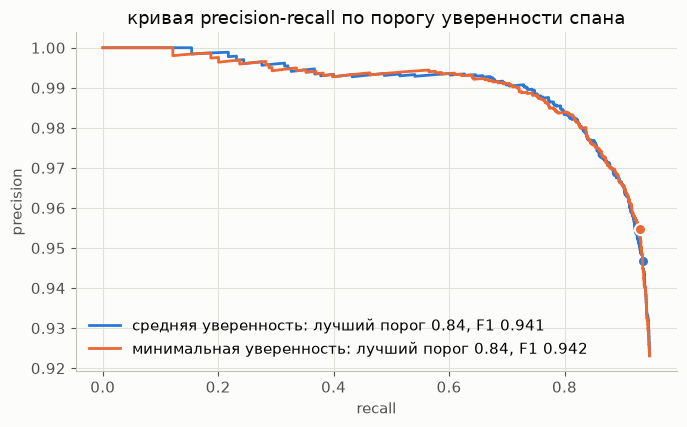

предсказанных спанов на validation 4226; потолок recall при пороге 0: 0.9475


In [37]:
if '6.5' in BONUS_TASKS:
    def span_rows(gold_tags, tags, probs):
        rows = []
        for i, (g, t, c) in enumerate(zip(gold_tags, tags, probs)):
            g_spans = set(bio_to_spans(g))
            for s in bio_to_spans(t):
                rows.append(dict(sent=i, span=s, hit=s in g_spans, mean=float(np.mean(c[s[0]:s[1]])), min=float(np.min(c[s[0]:s[1]]))))
        return rows


    def pr_curve(rows, key, n_gold):
        order = sorted(rows, key=lambda r: -r[key])
        hits = np.cumsum([r['hit'] for r in order])
        precision = hits / np.arange(1, len(order) + 1)
        recall = hits / n_gold
        f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
        return np.array([r[key] for r in order]), precision, recall, f1


    def filtered_scores(gold_tags, tags, rows, key, thr):
        kept = collections.defaultdict(list)
        for r in rows:
            if r[key] >= thr:
                kept[r['sent']].append(r['span'])
        return entity_scores(gold_tags, [spans_to_bio(kept[i], len(t)) for i, t in enumerate(tags)])


    val_tags, val_probs = predict_word_tags(model, val_tokens, return_probs=True)
    test_tags, test_probs = predict_word_tags(model, test_tokens, return_probs=True)
    val_rows, test_rows = span_rows(val_gold, val_tags, val_probs), span_rows(test_gold, test_tags, test_probs)
    n_val_gold = sum(len(bio_to_spans(g)) for g in val_gold)

    threshold_results = {}
    fig, ax = plt.subplots(figsize=(7, 4.4))
    for key, label, color in [('mean', 'средняя уверенность', '#2a78d6'), ('min', 'минимальная уверенность', '#eb6834')]:
        conf, precision, recall, f1 = pr_curve(val_rows, key, n_val_gold)
        valid = np.flatnonzero(np.append(conf[1:] != conf[:-1], True))
        best = int(valid[np.argmax(f1[valid])])
        thr = float(conf[best])
        val_at_thr = filtered_scores(val_gold, val_tags, val_rows, key, thr)
        test_at_thr = filtered_scores(test_gold, test_tags, test_rows, key, thr)
        assert abs(val_at_thr['f1_micro'] - f1[best]) < 1e-9
        threshold_results[key] = dict(threshold=thr, val=val_at_thr, test=test_at_thr, val_f1_no_threshold=float(f1[-1]),
                                      test_f1_no_threshold=filtered_scores(test_gold, test_tags, test_rows, key, 0.0)['f1_micro'])
        row = threshold_results[key]
        print(f'{label}: порог {thr:.3f}; validation F1 {row["val_f1_no_threshold"]:.4f} -> {val_at_thr["f1_micro"]:.4f} '
              f'(P {val_at_thr["precision"]:.3f}, R {val_at_thr["recall"]:.3f}); test F1 {row["test_f1_no_threshold"]:.4f} -> {test_at_thr["f1_micro"]:.4f} '
              f'(P {test_at_thr["precision"]:.3f}, R {test_at_thr["recall"]:.3f}); отброшено спанов на validation {np.mean([r[key] < thr for r in val_rows]):.1%}')
        ax.plot(recall, precision, color=color, label=f'{label}: лучший порог {thr:.2f}, F1 {f1[best]:.3f}')
        ax.plot(recall[best], precision[best], 'o', color=color, markersize=8, markeredgecolor='#fcfcfb', markeredgewidth=1.5)
    ax.set_xlabel('recall')
    ax.set_ylabel('precision')
    ax.set_title('кривая precision-recall по порогу уверенности спана')
    ax.grid(True)
    ax.legend(loc='lower left')
    plt.tight_layout()
    plt.show()
    print(f'предсказанных спанов на validation {len(val_rows)}; потолок recall при пороге 0: {recall[-1]:.4f}')

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Порог выбираю на validation, а проверяю на test. Для средней уверенности лучший порог 0.838: F1 на validation растёт с 0.9352 до 0.9414, на test с 0.9317 до 0.9353 (+0.004), отбрасывается 3.7% спанов. Для минимальной уверенности лучший порог 0.842: validation 0.9422, test 0.9365 (+0.005), отбрасывается 5.1% спанов. Прирост небольшой, потому что модель и так точна (precision 0.923 на validation), и порог срезает в основном немногие неуверенные спаны.

Минимальная уверенность строже: одного сомнительного слова хватает, чтобы выкинуть весь спан. Это как раз ошибки границы, когда модель не уверена, входит ли в название последнее слово или кавычка. Средняя сглаживает такое слово уверенными соседями. Поэтому при почти одинаковом пороге минимальная даёт на test precision выше (0.950 против 0.942), а recall ниже (0.924 против 0.929).

Поднять recall порог не может. Он только убирает предсказанные спаны, верных от этого не прибавляется, а знаменатель recall, число истинных сущностей, не меняется. Потолок recall задан порогом 0 и равен 0.9475 на validation.

In [38]:
bonus = {}
if '6.2' in BONUS_TASKS:
    bonus['6.2'] = dict(other_model=OTHER_ID, other_revision=OTHER_REVISION, other_lr=OTHER_LR, compare=compare)
if '6.3' in BONUS_TASKS:
    bonus['6.3'] = shift_results
if '6.4' in BONUS_TASKS:
    bonus['6.4'] = speed
if '6.5' in BONUS_TASKS:
    bonus['6.5'] = threshold_results
if bonus:
    (ARTIFACTS / 'bonus_metrics.json').write_text(json.dumps(json_ready(dict(fast_mode=FAST_MODE, **bonus)), ensure_ascii=False, indent=2),
                                                  encoding='utf-8')
    print('бонусы сохранены:', sorted(bonus))

бонусы сохранены: ['6.2', '6.3', '6.4', '6.5']
